# HFR single-point time evolution
Pick one test and one current-density point, run the DAE to steady state, and inspect the time evolution of all key variables.

**Workflow:** edit the *Parameters* cell -> run all -> read the plots.

In [ ]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve()
while not (PROJECT_ROOT / 'setup.py').exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError('Cannot find project root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path
import json
from solve_dae.integrate import solve_dae
ROOT = Path("../..").resolve()
sys.path.insert(0, str(ROOT / "scripts" / "Experimental"))
from simulate_HFR import build_cell, build_atol, soc_cutoff_event
from rfbmodel1D.parameters.params import membraneparams, SimulationParams, Vars, cellparams, cathodeparams, anodeparams


## -- Parameters --

In [13]:
# -- test / point selection -----------------------------------------------------
TEST_NO  = 5        # integer 1-29
MODE     = "discharge"   # "charge" or "discharge"
J_INDEX  = 7      # index into the current-density list for the chosen mode (0-based)

# -- solver settings ------------------------------------------------------------
TF     = 1800
RTOL   = 1e-5
STRIDE = 1

# -- fit results ----------------------------------------------------------------
# Path relative to scripts/Experimental/fit_results/, or None to use defaults
FIT_DIR = ROOT / "results" / "test fitting" / f"test {TEST_NO}"
HFR_FIT    = sorted(FIT_DIR.glob(f"fit_v2_test{TEST_NO}_*.json"))[-1].name
E_CELL_FIT = sorted(FIT_DIR.glob(f"fit_e_cell_test{TEST_NO}_*.json"))[-1].name

# -- apply HFR membrane params --------------------------------------------------
if HFR_FIT is not None:
    with open(FIT_DIR / HFR_FIT) as f:
        _hfr = json.load(f)
    _p = _hfr["params"]
    _s = _hfr["settings"]
    membraneparams.k_sorp_vw   = _p["k_vw_sorp"]
    membraneparams.k_desorp_vw = _p["S_desorp"] * _p["k_vw_sorp"]
    membraneparams.k_sorp_lw   = _p["k_lw_sorp"]
    membraneparams.k_desorp_lw = _p["S_desorp"] * _p["k_lw_sorp"]
    membraneparams.k_ca_lw     = _p["k_ca"]
    membraneparams.sf_D        = _s["sf_D"]
    cellparams.vanadium_uptake = False
    R_EXTRA = _p["R_extra (\u03a9\u00b7cm\u00b2)"] / 1e4
    print(f"HFR membrane params loaded from: {HFR_FIT}")

# -- apply E-cell kinetic params ------------------------------------------------
if E_CELL_FIT is not None:
    with open(FIT_DIR / E_CELL_FIT) as f:
        _ec = json.load(f)
    k_ca  = _ec["params"]["k_ca"]
    j0_an = _ec["params"]["j0_an"]
    print(f"E-cell params loaded from: {E_CELL_FIT}")

cathodeparams.reaction_rate_constant = k_ca
anodeparams.j_0                      = j0_an
print(f"k_ca = {k_ca:.4e} m/s   j0_an = {j0_an:.4e} A/m²")


HFR membrane params loaded from: fit_v2_test5_20260613_185943.json
E-cell params loaded from: fit_e_cell_test5_20260614_000424.json
k_ca = 1.7335e-07 m/s   j0_an = 2.7748e+03 A/m²


In [14]:
# -- load experimental data and pick the point ---------------------------------
csv  = ROOT / "data" / "experimental" / "E_cell.csv"
data = pd.read_csv(csv)
data = data[data["test_no"] == TEST_NO]
E_list = data["value (V)"].values
E_exp   = float(E_list[J_INDEX])
# -- load experimental data and pick the point ---------------------------------
csv  = ROOT / "data" / "experimental" / "HFR.csv"
data = pd.read_csv(csv)
data = data[data["test_no"] == TEST_NO]

soc = data["SOC"].iloc[0]
T   = data["T(°C)"].iloc[0]
Q_v = data["Q_v (ml/min)"].iloc[0]

mode_data = data[data["mode"] == MODE]
j_list    = mode_data["j_appl (A/m2)"].values
HFR_list  = mode_data["value (ohm cm2)"].values

j_appl_raw = float(j_list[J_INDEX])
j_appl     = j_appl_raw if MODE == "charge" else -j_appl_raw   # negative for discharge
HFR_exp    = float(HFR_list[J_INDEX])


print(f"Test {TEST_NO}: SOC={soc}, T={T}°C, Q_v={Q_v} ml/min")
print(f"Mode: {MODE}  |  j_appl = {j_appl:+.0f} A/m²  |  HFR_exp = {HFR_exp:.4f} Ω·cm²")

Test 5: SOC=0.1, T=32°C, Q_v=45 ml/min
Mode: discharge  |  j_appl = -2023 A/m²  |  HFR_exp = 0.9240 Ω·cm²


## Run simulation

In [15]:
cell, y0, yp0 = build_cell(soc, j_appl, T, Q_v)
atol          = build_atol(cell)
jac_sparsity  = cell.compute_jac_sparsity(y0, yp0)

t0_wall = time.time()
sol = solve_dae(
    cell.dae_residual_full_cell,
    (0.0, TF), y0, yp0,
    method="BDF", atol=atol, rtol=RTOL,
    events=soc_cutoff_event, jac_sparsity=jac_sparsity
)
elapsed = time.time() - t0_wall

tsol = sol.t
ysol = sol.y
print(f"\n✓ Done in {elapsed:.1f} s  |  {len(tsol)} time points  |  reached t={tsol[-1]:.1f} s")
print(f"Success: {sol.success}  |  {sol.message}")


✓ Done in 2.9 s  |  57 time points  |  reached t=1800.0 s
Success: True  |  The solver successfully reached the end of the integration interval.


## HFR at final time

In [16]:
kappa_io_ca = cell.cathode.kappa_io
sigma_ca    = np.ones_like(kappa_io_ca) * cell.cathode.eff_conductivity
dx_ca       = cell.mesh.cathode_mesh.dx * cell.cathode.thickness
R_cathode   = float(np.sum(dx_ca / (sigma_ca + kappa_io_ca)))

kappa_io_m = cell.membrane.kappa_io
dx_m       = cell.mesh.membrane_mesh.dx * cell.membrane.thickness
R_membrane = float(np.sum(dx_m / kappa_io_m))

R_ACL  = cell.anode.thickness  / cell.anode.eff_conductivity
R_AGDL = cell.agdl.thickness   / cell.agdl.eff_conductivity
R_BP   = cell.thickness_BP / cell.sigma_BP
R_CC   = cell.thickness_CC / cell.sigma_CC

HFR_sim = (R_cathode + R_membrane + R_ACL + R_AGDL + R_BP + R_CC + R_EXTRA) * 1e4

print(f"HFR simulated : {HFR_sim:.4f} Ω·cm²")
print(f"HFR experimental: {HFR_exp:.4f} Ω·cm²")
print(f"Error: {HFR_sim - HFR_exp:+.4f} Ω·cm²")

HFR simulated : 0.9698 Ω·cm²
HFR experimental: 0.9240 Ω·cm²
Error: +0.0458 Ω·cm²


## Time evolution — full-cell diagnostics

In [17]:
# -- layout --------------------------------------------------------------------
Nc    = cell.mesh.cathode_mesh.n_x
Nm    = cell.mesh.membrane_mesh.n_x
n_tank = cell.layout.n_vars_tank
n_ca   = cell.layout.n_vars_cathode
n_mem  = cell.layout.n_vars_membrane
n_an   = cell.layout.n_vars_anode

off_tank = 0
off_ca   = off_tank + n_tank
off_mem  = off_ca   + Nc * n_ca
off_an   = off_mem  + Nm * n_mem

y_ca_all  = ysol[off_ca:off_mem, :].reshape(Nc, n_ca, -1)   # (Nc, n_ca, Nt)
y_mem_all = ysol[off_mem:off_an, :].reshape(Nm, n_mem, -1)  # (Nm, n_mem, Nt)
y_an_all  = ysol[off_an:off_an + n_an, :]                    # (n_an, Nt)
# cathode vars
c_V4_ca   = y_ca_all[:, 0, :]
c_V5_ca   = y_ca_all[:, 1, :]
Phi_el_ca    = y_ca_all[:, 4, :]
Phi_io_ca    = y_ca_all[:, 5, :]
x_ca_mm     = cell.cathode.thickness * cell.mesh.cathode_mesh.x_grid *1000  # (Nc, Nt) 

# anode variables
c_vw_acl  = y_an_all[0, :]
c_H2_acl  = y_an_all[1, :]
s_acl     = y_an_all[2, :]
eta_acl   = y_an_all[3, :]
c_vw_agdl = y_an_all[4, :]
c_H2_agdl = y_an_all[5, :]
s_agdl    = y_an_all[6, :]

# membrane
lambda_mem      = y_mem_all[:, 0, :]   # (Nm, Nt)
lambda_mem_mean = np.mean(lambda_mem, axis=0)
lambda_mem_min  = np.min(lambda_mem,  axis=0)
lambda_mem_max  = np.max(lambda_mem,  axis=0)

# cathode H+
c_H_ca = y_ca_all[:, 2, :]

# tank
c_V4   = ysol[0, :]
c_V5   = ysol[1, :]
c_H    = ysol[2, :]
c_HSO4 = ysol[3, :]
V_tank = ysol[4, :]
den         = c_V4 + c_V5
SOC_time    = np.divide(c_V5, den, out=np.zeros_like(c_V5), where=den > 0)

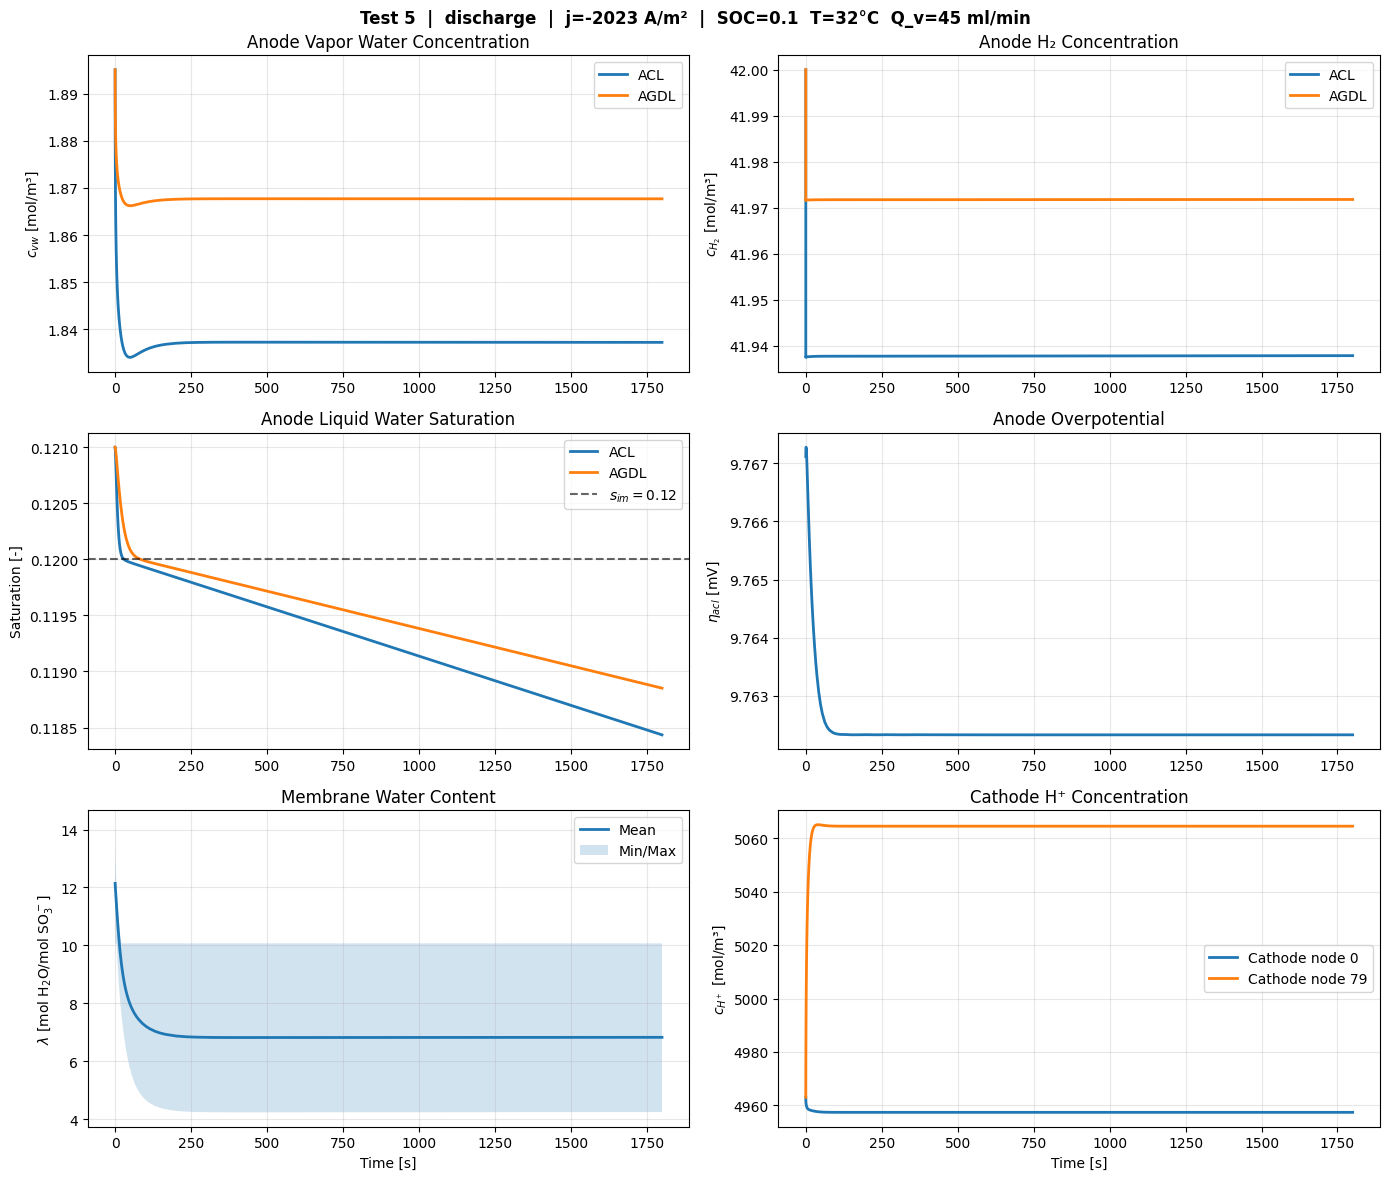

In [18]:
title_base = (
    f"Test {TEST_NO}  |  {MODE}  |  j={j_appl:+.0f} A/m²  "
    f"|  SOC={soc}  T={T}°C  Q_v={Q_v} ml/min"
)

fig1, axes = plt.subplots(3, 2, figsize=(14, 12))

axes[0, 0].plot(tsol, c_vw_acl,  lw=2, label="ACL")
axes[0, 0].plot(tsol, c_vw_agdl, lw=2, label="AGDL")
axes[0, 0].set_ylabel(r"$c_{vw}$ [mol/m³]")
axes[0, 0].set_title("Anode Vapor Water Concentration")
axes[0, 0].legend(); axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(tsol, c_H2_acl,  lw=2, label="ACL")
axes[0, 1].plot(tsol, c_H2_agdl, lw=2, label="AGDL")
axes[0, 1].set_ylabel(r"$c_{H_2}$ [mol/m³]")
axes[0, 1].set_title("Anode H₂ Concentration")
axes[0, 1].legend(); axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].plot(tsol, s_acl,  lw=2, label="ACL")
axes[1, 0].plot(tsol, s_agdl, lw=2, label="AGDL")
axes[1, 0].axhline(0.12, color="k", ls="--", alpha=0.6, label=r"$s_{im}=0.12$")
axes[1, 0].set_ylabel("Saturation [-]")
axes[1, 0].set_title("Anode Liquid Water Saturation")
axes[1, 0].legend(); axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(tsol, eta_acl * 1e3, lw=2)
axes[1, 1].set_ylabel(r"$\eta_{acl}$ [mV]")
axes[1, 1].set_title("Anode Overpotential")
axes[1, 1].grid(True, alpha=0.3)

axes[2, 0].plot(tsol, lambda_mem_mean, lw=2, label="Mean")
axes[2, 0].fill_between(tsol, lambda_mem_min, lambda_mem_max, alpha=0.2, label="Min/Max")
axes[2, 0].set_xlabel("Time [s]")
axes[2, 0].set_ylabel(r"$\lambda$ [mol H$_2$O/mol SO$_3^-$]")
axes[2, 0].set_title("Membrane Water Content")
axes[2, 0].legend(); axes[2, 0].grid(True, alpha=0.3)

axes[2, 1].plot(tsol, c_H_ca[0, :],    lw=2, label="Cathode node 0")
axes[2, 1].plot(tsol, c_H_ca[-1, :],   lw=2, label=f"Cathode node {Nc-1}")
axes[2, 1].set_xlabel("Time [s]")
axes[2, 1].set_ylabel(r"$c_{H^+}$ [mol/m³]")
axes[2, 1].set_title("Cathode H⁺ Concentration")
axes[2, 1].legend(); axes[2, 1].grid(True, alpha=0.3)

fig1.suptitle(title_base, fontsize=12, fontweight="bold")
fig1.tight_layout()
plt.show()

## Membrane λ evolution

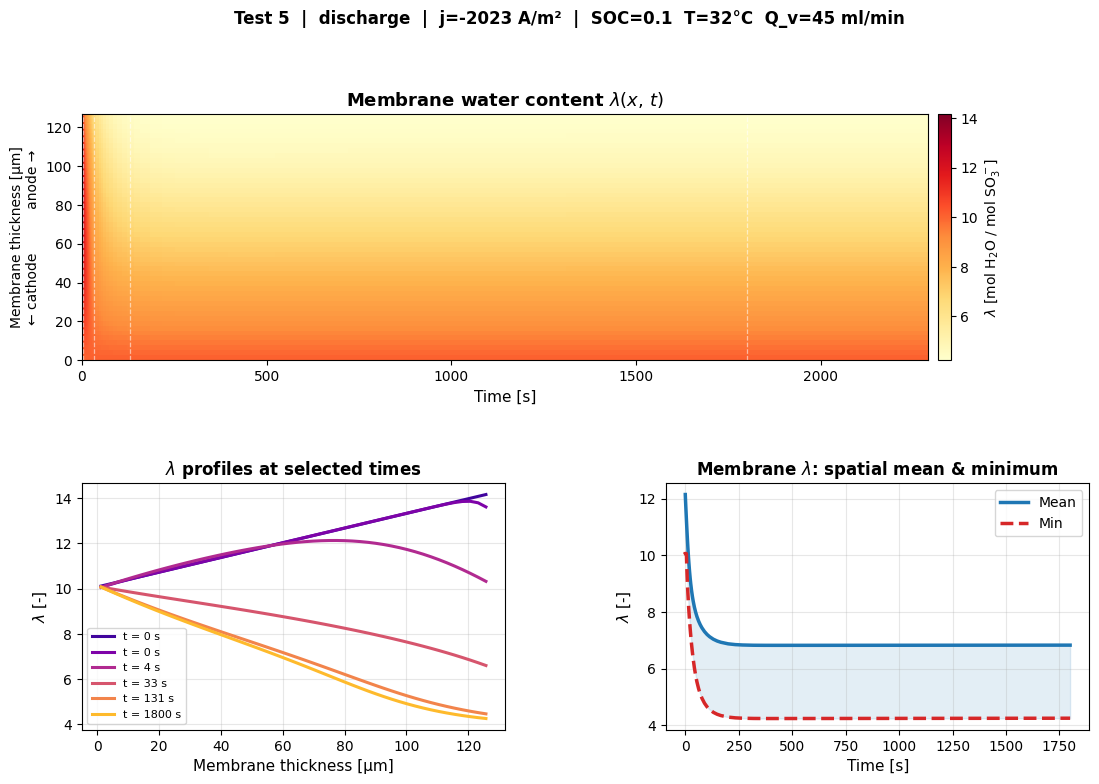

In [19]:
# physical membrane coordinates [µm]
edges_m = np.concatenate([[0.0], np.cumsum(cell.mesh.membrane_mesh.dx * cell.membrane.thickness)])
x_mem_um = 0.5 * (edges_m[:-1] + edges_m[1:]) * 1e6

n_snap     = 6
t_idx      = np.round(np.linspace(0, len(tsol) - 1, n_snap)).astype(int)
snap_colors = plt.cm.plasma(np.linspace(0.1, 0.85, n_snap))

fig3 = plt.figure(figsize=(13, 8))
gs   = gridspec.GridSpec(2, 2, figure=fig3, hspace=0.5, wspace=0.38)
ax_heat = fig3.add_subplot(gs[0, :])
ax_snap = fig3.add_subplot(gs[1, 0])
ax_mean = fig3.add_subplot(gs[1, 1])

im = ax_heat.pcolormesh(tsol, x_mem_um, lambda_mem, cmap="YlOrRd", shading="auto")
cb = fig3.colorbar(im, ax=ax_heat, pad=0.01)
cb.set_label(r"$\lambda$ [mol H$_2$O / mol SO$_3^-$]", fontsize=10)
for idx in t_idx:
    ax_heat.axvline(tsol[idx], color="white", lw=0.9, ls="--", alpha=0.55)
ax_heat.set_xlabel("Time [s]", fontsize=11)
ax_heat.set_ylabel("Membrane thickness [µm]\n← cathode          anode ->", fontsize=10)
ax_heat.set_title(r"Membrane water content $\lambda(x,\,t)$", fontsize=13, fontweight="bold")

for k, idx in enumerate(t_idx):
    ax_snap.plot(x_mem_um, lambda_mem[:, idx],
                 color=snap_colors[k], lw=2.2,
                 label=f"t = {tsol[idx]:.0f} s")
ax_snap.set_xlabel("Membrane thickness [µm]", fontsize=11)
ax_snap.set_ylabel(r"$\lambda$ [-]", fontsize=11)
ax_snap.set_title(r"$\lambda$ profiles at selected times", fontsize=12, fontweight="bold")
ax_snap.legend(fontsize=8, loc="best")
ax_snap.grid(True, alpha=0.3)

ax_mean.plot(tsol, lambda_mem_mean, lw=2.5, color="tab:blue", label="Mean")
ax_mean.plot(tsol, lambda_mem_min,  lw=2.5, color="tab:red", ls="--", label="Min")
ax_mean.fill_between(tsol, lambda_mem_min, lambda_mem_mean, alpha=0.12, color="tab:blue")
ax_mean.set_xlabel("Time [s]", fontsize=11)
ax_mean.set_ylabel(r"$\lambda$ [-]", fontsize=11)
ax_mean.set_title(r"Membrane $\lambda$: spatial mean & minimum", fontsize=12, fontweight="bold")
ax_mean.legend(fontsize=10)
ax_mean.grid(True, alpha=0.3)

fig3.suptitle(title_base, fontsize=12, fontweight="bold", y=1.01)
plt.show()

## Cathode species

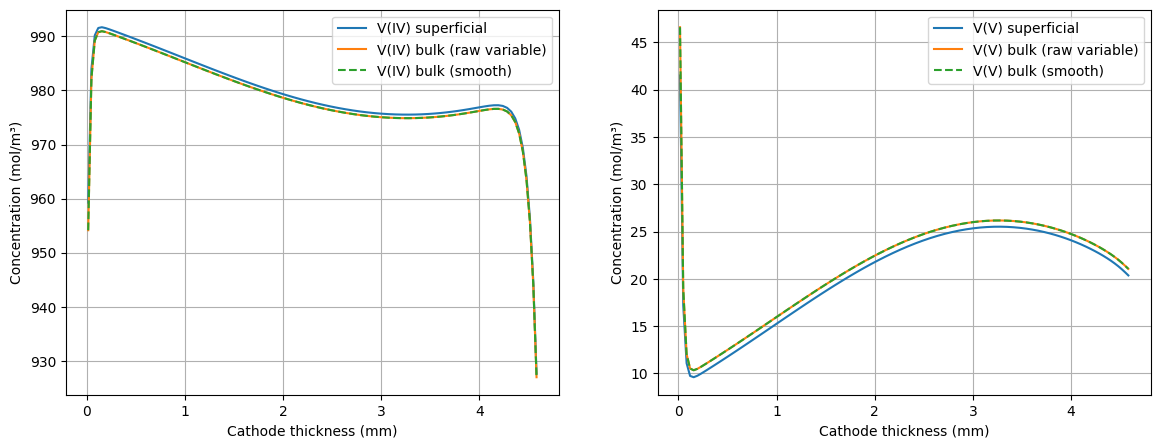

In [20]:
# -- Superficial (athode concentrations over time --------
from rfbmodel1D.electrochem.butler_volmer import cathode_surface_concentrations

c_eta   = np.concatenate([c_V4_ca[:, -1], c_V5_ca[:, -1], c_H_ca[:, -1]])
cell.compute_overpotential(Phi_el_ca[:, -1], Phi_io_ca[:, -1], c_eta, "cathode")
eta = cell.cathode.eta
c_s_V4, c_s_V5, c_V4, c_V5, Psi3, Psi4, beta_0 = cathode_surface_concentrations(
    cell, eta, c_V4_ca[:, -1], c_V5_ca[:, -1])
fig, axes = plt.subplots(1,2, figsize=(14,5))
axes[0].plot(x_ca_mm, c_s_V4, label = "V(IV) superficial")
axes[0].plot(x_ca_mm, c_V4_ca[:, -1], label = "V(IV) bulk (raw variable)")
axes[0].plot(x_ca_mm, c_V4, label = "V(IV) bulk (smooth)", ls="--")
axes[0].set_xlabel("Cathode thickness (mm)")
axes[0].set_ylabel("Concentration (mol/m³)")
axes[0].legend()
axes[0].grid(True)
axes[1].plot(x_ca_mm, c_s_V5, label = "V(V) superficial")
axes[1].plot(x_ca_mm, c_V5_ca[:, -1], label = "V(V) bulk (raw variable)")
axes[1].plot(x_ca_mm, c_V5, label = "V(V) bulk (smooth)", ls="--")
axes[1].set_xlabel("Cathode thickness (mm)")
axes[1].set_ylabel("Concentration (mol/m³)")
axes[1].legend()
axes[1].grid(True)
plt.show()

In [21]:
print("In plane superficial velocity ", cell.cathode.u_ip*1000, "mm/s")
print("In plane interstitial velocity ", cell.cathode.u_ip / cell.cathode.porosity * 1000, "mm/s")
print("Q_ca is", cell.cathode.Q_ca *1000*1000*60, "m³/s")
print("Q_total is", cell.cathode.Q_total*1000*1000*60, "mL/min")
print("Percentage of flowrate that goes through the cathode is", (cell.cathode.Q_ca / cell.cathode.Q_total) * 100, "%")

In plane superficial velocity  2.7851635432568056 mm/s
In plane interstitial velocity  2.9629399396348997 mm/s
Q_ca is 38.43525689694391 m³/s
Q_total is 44.99999999999999 mL/min
Percentage of flowrate that goes through the cathode is 85.41168199320872 %


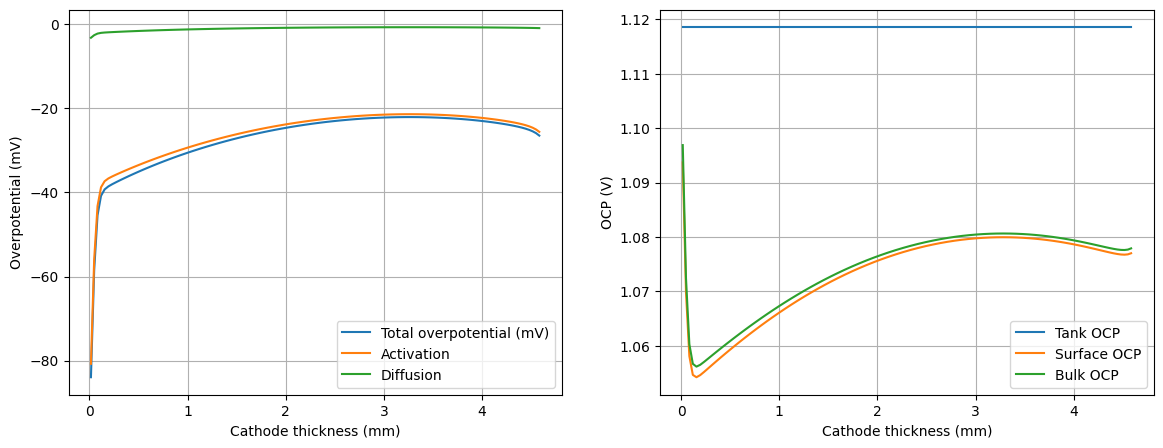

In [22]:
decompose = cell.decompose_overpotential(ysol[:,-1])
eta_total = decompose["eta_total"]
eta_act   = decompose["eta_act"]
eta_diff  = decompose["eta_diff"]
OCP_bulk  = decompose["OCP_bulk"]
OCP_surf = decompose["OCP_surf"]
OCP_tank = decompose["OCP_tank"]
fig, axes = plt.subplots(1,2, figsize=(14,5))
axes[0].plot(x_ca_mm, eta_total * 1e3, label="Total overpotential (mV)")
axes[0].plot(x_ca_mm, eta_act * 1e3, label="Activation")
axes[0].plot(x_ca_mm, eta_diff * 1e3, label="Diffusion")
axes[0].set_xlabel("Cathode thickness (mm)")
axes[0].set_ylabel("Overpotential (mV)")
axes[0].legend()
axes[0].grid(True)
axes[1].plot(x_ca_mm, OCP_tank*np.ones_like(x_ca_mm), label="Tank OCP")
axes[1].plot(x_ca_mm, OCP_surf, label="Surface OCP")
axes[1].plot(x_ca_mm, OCP_bulk, label="Bulk OCP")
axes[1].set_xlabel("Cathode thickness (mm)")
axes[1].set_ylabel("OCP (V)")
axes[1].legend()
axes[1].grid(True)


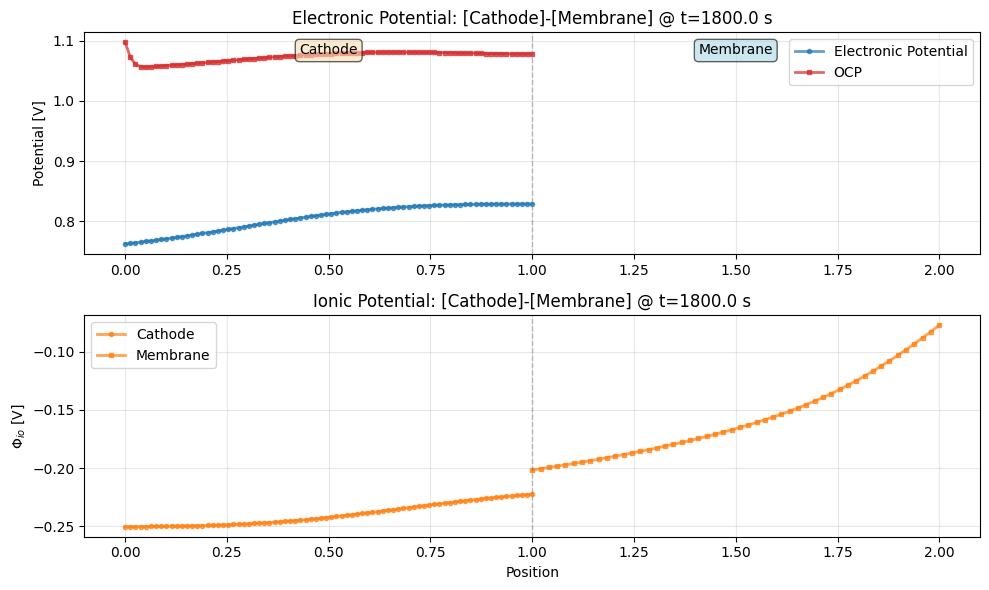

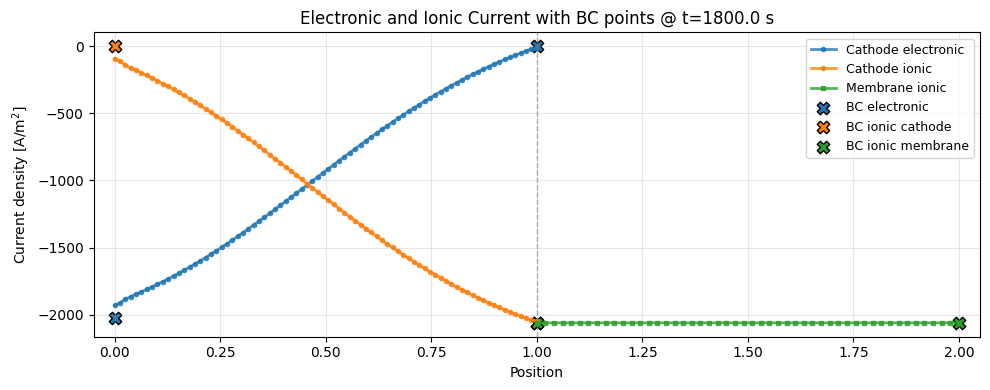

Electronic BC: galvanostatic neumann -> -2023.255814 -0.0
Ionic cathode BC: neumann neumann -> -0.0 -2060.4136039169375
Ionic membrane BC: neumann dirichlet -> -2060.4136039165096 -2060.5809021814457
Source used: continuation only


In [23]:
import numpy as np
import matplotlib.pyplot as plt

# ============= Use latest available solution (last time) =============
t_plot = tsol
y_plot = ysol
src_label = "continuation only"

y_last = y_plot[:, -1]
t_last = float(t_plot[-1])

# Layout
Nc = cell.mesh.cathode_mesh.n_x
Nm = cell.mesh.membrane_mesh.n_x
n_tank = cell.layout.n_vars_tank
n_ca = cell.layout.n_vars_cathode
n_mem = cell.layout.n_vars_membrane
off_tank = 0
off_ca = off_tank + n_tank
off_mem = off_ca + Nc * n_ca

# Last-time cathode/membrane states
y_ca_last = y_last[off_ca:off_mem].reshape(Nc, n_ca)
y_mem_last = y_last[off_mem:off_mem + Nm * n_mem].reshape(Nm, n_mem)

# Cathode order: [c_V4, c_V5, c_H, c_HSO4, Phi_el, Phi_io]
# Membrane order: [lambda, Phi_io]
c_ca = y_ca_last[:, :4]
phi_el_ca = y_ca_last[:, 4]
phi_io_ca = y_ca_last[:, 5]
phi_io_mem = y_mem_last[:, 1]

# Combined 1D plotting coordinates (dimensionless domains)
L_ca           = 1.0
L_mem          = 1.0
x_combined_ca  = np.linspace(0.0, L_ca, Nc)
x_combined_mem = np.linspace(L_ca, L_ca + L_mem, Nm)

# OCP in cathode at last time
V_OCP_ca = np.array([cell.compute_OCP(c_ca[i, :], "cathode") for i in range(Nc)])

# ============= PLOT 1: POTENTIALS (phi_el, phi_io) - Cathode & Membrane =============
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6))

ax1.plot(x_combined_ca, phi_el_ca, "o-", lw=2, ms=3, label="Electronic Potential", color="tab:blue", alpha=0.7)
ax1.plot(x_combined_ca, V_OCP_ca, "s-", lw=2, ms=3, label="OCP", color="tab:red", alpha=0.7)
ax1.axvline(x=L_ca, color="gray", ls="--", alpha=0.5, lw=1)
ax1.set_ylabel("Potential [V]")
ax1.set_title(f"Electronic Potential: [Cathode]-[Membrane] @ t={t_last:.1f} s")
ax1.grid(True, alpha=0.3)
ax1.legend(loc="best")
ax1.set_xlim(-0.1, L_ca + L_mem + 0.1)

y_range = ax1.get_ylim()
y_pos = y_range[0] + (y_range[1] - y_range[0]) * 0.90
ax1.text(L_ca / 2, y_pos, "Cathode", ha="center",
         bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.6))
ax1.text(L_ca + L_mem / 2, y_pos, "Membrane", ha="center",
         bbox=dict(boxstyle="round", facecolor="lightblue", alpha=0.6))

ax2.plot(x_combined_ca, phi_io_ca, "o-", lw=2, ms=3, label="Cathode", color="tab:orange", alpha=0.7)
ax2.plot(x_combined_mem, phi_io_mem, "s-", lw=2, ms=3, label="Membrane", color="tab:orange", alpha=0.7)
ax2.axvline(x=L_ca, color="gray", ls="--", alpha=0.5, lw=1)
ax2.set_xlabel("Position")
ax2.set_ylabel(r"$\Phi_{io}$ [V]")
ax2.set_title(f"Ionic Potential: [Cathode]-[Membrane] @ t={t_last:.1f} s")
ax2.grid(True, alpha=0.3)
ax2.legend(loc="best")
ax2.set_xlim(-0.1, L_ca + L_mem + 0.1)

plt.tight_layout()
plt.show()

# ============= PLOT 2: Ionic + Electronic Current + BC points =============
def bc_to_current(phi, bc, coeff, dx, side):
    if bc.type == "neumann":
        dphi_dx = bc.value
    elif bc.type == "galvanostatic":
        dphi_dx = -bc.value / coeff
    elif bc.type == "dirichlet":
        if side == "left":
            dphi_dx = (phi[0] - bc.value) / (dx[0] / 2)
        elif side == "right":
            dphi_dx = (bc.value - phi[-1]) / (dx[-1] / 2)
        else:
            raise ValueError("side must be 'left' or 'right'")
    else:
        return np.nan
    return -coeff * dphi_dx

# Geometry and transport coefficients
dx_ca = cell.mesh.cathode_mesh.dx * cell.cathode.thickness
dx_m = cell.mesh.membrane_mesh.dx * cell.membrane.thickness
edges_m = np.concatenate([[0.0], np.cumsum(dx_m)])
edges_ca = np.concatenate([[0.0], np.cumsum(dx_ca)])
x_center_m = 0.5 * (edges_m[:-1] + edges_m[1:])
dx_face_m = x_center_m[1:] - x_center_m[:-1]
x_center_ca = 0.5 * (edges_ca[:-1] + edges_ca[1:])
dx_face_ca = x_center_ca[1:] - x_center_ca[:-1]

sigma_ca = float(cell.cathode.eff_conductivity)
kappa_ca = cell.cathode.kappa_io

kappa_m_arr = np.asarray(cell.membrane.kappa_io)
if kappa_m_arr.ndim == 0:
    kappa_m_arr = np.full(Nm, float(kappa_m_arr))

# Node-wise currents
grad_faces_ca = (phi_el_ca[1:] - phi_el_ca[:-1]) / dx_face_ca
grad_nodes_phi_el = np.empty_like(phi_el_ca)
grad_nodes_phi_el[0] = grad_faces_ca[0]
grad_nodes_phi_el[1:-1] = 0.5 * (grad_faces_ca[:-1] + grad_faces_ca[1:])
grad_nodes_phi_el[-1] = grad_faces_ca[-1]
grad_faces_io_ca = (phi_io_ca[1:] - phi_io_ca[:-1]) / dx_face_ca
grad_nodes_phi_io_ca = np.empty_like(phi_io_ca)
grad_nodes_phi_io_ca[0] = grad_faces_io_ca[0]
grad_nodes_phi_io_ca[1:-1] = 0.5 * (grad_faces_io_ca[:-1] + grad_faces_io_ca[1:])
grad_nodes_phi_io_ca[-1] = grad_faces_io_ca[-1]
i_el_ca = -sigma_ca * grad_nodes_phi_el
i_io_ca = -kappa_ca * grad_nodes_phi_io_ca

bc_phi_el_ca_L = cell.bc[Vars.phi_el]["cathode"]["left"]
bc_phi_el_ca_R = cell.bc[Vars.phi_el]["cathode"]["right"]
bc_phi_io_ca_L = cell.bc[Vars.phi_io]["cathode"]["left"]
bc_phi_io_ca_R = cell.bc[Vars.phi_io]["cathode"]["right"]
bc_phi_io_m_L = cell.bc[Vars.phi_io]["membrane"]["left"]
bc_phi_io_m_R = cell.bc[Vars.phi_io]["membrane"]["right"]

assert bc_phi_io_m_L.type == "neumann", "Expected left membrane phi_io BC to be neumann"
assert bc_phi_io_m_R.type == "dirichlet", "Expected right membrane phi_io BC to be dirichlet"

kappa_faces = 2.0 * kappa_m_arr[:-1] * kappa_m_arr[1:] / (kappa_m_arr[:-1] + kappa_m_arr[1:] + 1e-30)
grad_faces = (phi_io_mem[1:] - phi_io_mem[:-1]) / dx_face_m
flux_faces = -kappa_faces * grad_faces

i_io_m_bc_L = -kappa_m_arr[0] * bc_phi_io_m_L.value
i_io_m_bc_R = -kappa_m_arr[-1] * (bc_phi_io_m_R.value - phi_io_mem[-1]) / (dx_m[-1] / 2)

i_io_mem = np.empty(Nm)
i_io_mem[0] = i_io_m_bc_L
i_io_mem[-1] = i_io_m_bc_R
if Nm > 2:
    i_io_mem[1:-1] = 0.5 * (flux_faces[:-1] + flux_faces[1:])

i_el_bc_L = bc_to_current(phi_el_ca, bc_phi_el_ca_L, sigma_ca, dx_ca, "left")
i_el_bc_R = bc_to_current(phi_el_ca, bc_phi_el_ca_R, sigma_ca, dx_ca, "right")
i_io_ca_bc_L = bc_to_current(phi_io_ca, bc_phi_io_ca_L, kappa_ca[0], dx_ca, "left")
i_io_ca_bc_R = bc_to_current(phi_io_ca, bc_phi_io_ca_R, kappa_ca[-1], dx_ca, "right")

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(x_combined_ca, i_el_ca, "o-", lw=2, ms=3, label="Cathode electronic", color="tab:blue", alpha=0.8)
ax.plot(x_combined_ca, i_io_ca, "o-", lw=2, ms=3, label="Cathode ionic", color="tab:orange", alpha=0.8)
ax.plot(x_combined_mem, i_io_mem, "s-", lw=2, ms=3, label="Membrane ionic", color="tab:green", alpha=0.8)
ax.axvline(x=L_ca, color="gray", ls="--", alpha=0.6, lw=1)

x_ca_L, x_ca_R = 0.0, L_ca
x_m_L, x_m_R = L_ca, L_ca + L_mem

ax.scatter([x_ca_L, x_ca_R], [i_el_bc_L, i_el_bc_R], marker="X", s=80, color="tab:blue", edgecolor="k", label="BC electronic")
ax.scatter([x_ca_L, x_ca_R], [i_io_ca_bc_L, i_io_ca_bc_R], marker="X", s=80, color="tab:orange", edgecolor="k", label="BC ionic cathode")
ax.scatter([x_m_L, x_m_R], [i_io_m_bc_L, i_io_m_bc_R], marker="X", s=80, color="tab:green", edgecolor="k", label="BC ionic membrane")

ax.set_xlabel("Position")
ax.set_ylabel(r"Current density [A/m$^2$]")
ax.set_title(f"Electronic and Ionic Current with BC points @ t={t_last:.1f} s")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9, loc="best")
ax.set_xlim(-0.05, L_ca + L_mem + 0.05)

plt.tight_layout()
plt.show()

print("Electronic BC:", bc_phi_el_ca_L.type, bc_phi_el_ca_R.type, "->", i_el_bc_L, i_el_bc_R)
print("Ionic cathode BC:", bc_phi_io_ca_L.type, bc_phi_io_ca_R.type, "->", i_io_ca_bc_L, i_io_ca_bc_R)
print("Ionic membrane BC:", bc_phi_io_m_L.type, bc_phi_io_m_R.type, "->", i_io_m_bc_L, i_io_m_bc_R)
print(f"Source used: {src_label}")